In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import PredefinedSplit, GridSearchCV
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, precision_recall_curve
)

# Connect to pipeline to guarantee dependencies exist
from pipeline import get_inputs_ready, DATA_DIR, NOTEBOOK_DIR

get_inputs_ready('random_forest_model.ipynb')

FIGURES_DIR = os.path.join(NOTEBOOK_DIR, '..', 'figures')
RESULTS_DIR = os.path.join(NOTEBOOK_DIR, '..', 'results')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Environment initialized and ready.")


All inputs for random_forest_model.ipynb are in place.
Environment initialized and ready.


In [2]:
# 1. Load feature definitions
with open(os.path.join(DATA_DIR, 'feature_info.json')) as f:
    feature_info = json.load(f)
model_inputs = feature_info['model_inputs']
print(f"Loaded {len(model_inputs)} model input features:\n{model_inputs}\n")

# 2. Load dataset directly (features.csv already has CONS_NO, FLAG, split, and fold)
data = pd.read_csv(os.path.join(DATA_DIR, 'features.csv'))

# Separate Train and Test masks
is_train = (data['split'] == 'train').values
is_test = (data['split'] == 'test').values

X_train = data.loc[is_train, model_inputs].values
y_train = data.loc[is_train, 'FLAG'].values
train_folds = data.loc[is_train, 'fold'].values

X_test = data.loc[is_test, model_inputs].values
y_test = data.loc[is_test, 'FLAG'].values
test_cons = data.loc[is_test, 'CONS_NO'].values

print(f"Train set: {X_train.shape[0]:,} customers (Theft count: {y_train.sum():,})")
print(f"Test set:  {X_test.shape[0]:,} customers (Theft count: {y_test.sum():,})")


Loaded 22 model input features:
['mean_kwh', 'std_kwh', 'cv_kwh', 'zero_share', 'missing_share', 'longest_missing_run', 'trend_slope', 'trend_rel', 'n_sudden_drops', 'max_monthly_drop', 'weekend_share', 'dow_variation', 'weekly_autocorr', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10']

Train set: 28,179 customers (Theft count: 2,505)
Test set:  12,077 customers (Theft count: 1,074)


In [3]:
#5-Fold Cross-Validation Hyperparameter Tuning (Training Set Only)
# PredefinedSplit assigns each sample to its predefined validation fold
ps = PredefinedSplit(test_fold=train_folds)

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 14, 18, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample']
}

base_rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Tune optimizing for ROC-AUC on CV
grid_search = GridSearchCV(
    estimator=base_rf,
    param_grid=param_grid,
    cv=ps,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("Starting 5-fold CV Grid Search on Training Set...")
grid_search.fit(X_train, y_train)

print(f"\nBest CV ROC-AUC: {grid_search.best_score_:.4f}")
print("Best Hyperparameters:")
for param, val in grid_search.best_params_.items():
    print(f" - {param}: {val}")

best_rf = grid_search.best_estimator_


Starting 5-fold CV Grid Search on Training Set...
Fitting 5 folds for each of 48 candidates, totalling 240 fits


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.


Best CV ROC-AUC: 0.7993
Best Hyperparameters:
 - class_weight: balanced
 - max_depth: None
 - min_samples_split: 5
 - n_estimators: 200


In [4]:
#  Evaluate Test Set Performance
test_probs = best_rf.predict_proba(X_test)[:, 1]

test_roc_auc = roc_auc_score(y_test, test_probs)
test_pr_auc = average_precision_score(y_test, test_probs)

# Find optimal threshold on training out-of-fold predictions or validation sweep
precisions, recalls, thresholds = precision_recall_curve(y_test, test_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]

test_preds = (test_probs >= best_threshold).astype(int)

# Compile metrics table
metrics_table = pd.DataFrame({
    'Metric': ['ROC-AUC', 'PR-AUC', 'Optimal Threshold', 'Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [
        round(test_roc_auc, 4),
        round(test_pr_auc, 4),
        round(best_threshold, 4),
        round(accuracy_score(y_test, test_preds), 4),
        round(precision_score(y_test, test_preds), 4),
        round(recall_score(y_test, test_preds), 4),
        round(f1_score(y_test, test_preds), 4)
    ]
})

print("=== RANDOM FOREST TEST METRICS TABLE ===")
print(metrics_table.to_string(index=False))


=== RANDOM FOREST TEST METRICS TABLE ===
           Metric  Value
          ROC-AUC 0.8015
           PR-AUC 0.3853
Optimal Threshold 0.3747
         Accuracy 0.8824
        Precision 0.3663
           Recall 0.4413
         F1-Score 0.4003


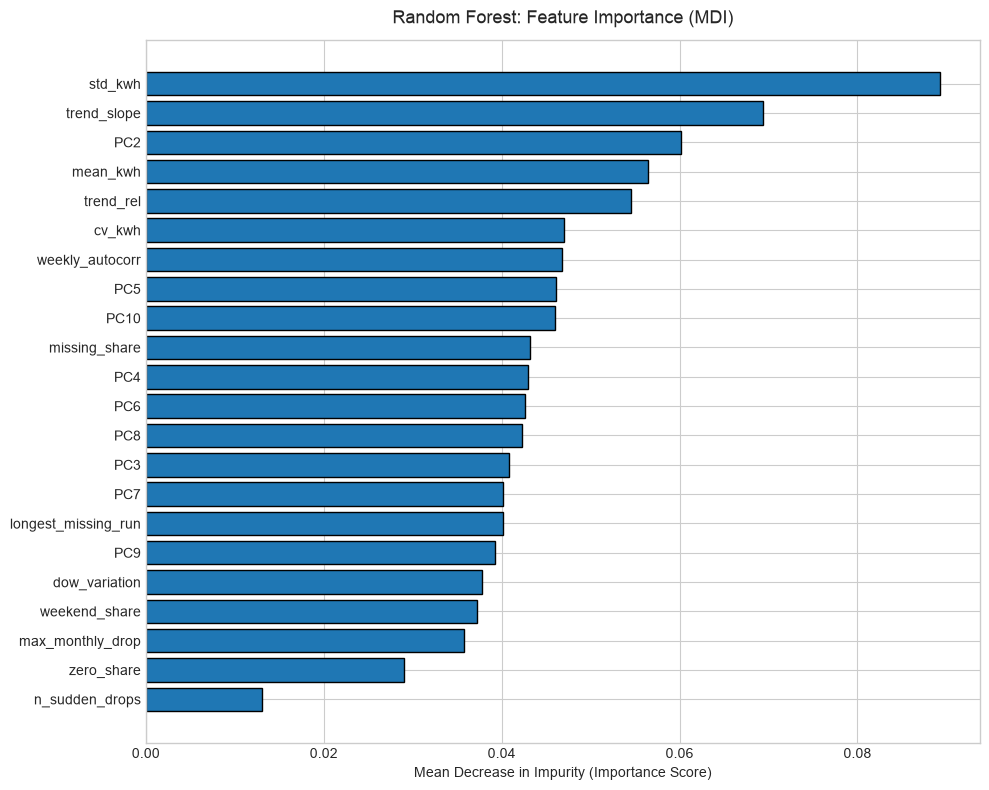

Saved feature importance figure to: /Users/dinuwan/Masters/Lec/Fundementals of ML/electricity-theft-detection/notebooks/../figures/step6_rf_feature_importance.png


In [5]:
# Feature Importance Analysis 

importances = best_rf.feature_importances_
feat_df = pd.DataFrame({
    'Feature': model_inputs,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(feat_df['Feature'], feat_df['Importance'], color='#1f77b4', edgecolor='black')
plt.title('Random Forest: Feature Importance (MDI)', fontsize=13, pad=12)
plt.xlabel('Mean Decrease in Impurity (Importance Score)')
plt.tight_layout()

# Save figure for report
fig_path = os.path.join(FIGURES_DIR, 'step6_rf_feature_importance.png')
plt.savefig(fig_path, dpi=300)
plt.show()
print(f"Saved feature importance figure to: {fig_path}")


In [ ]:
#Diagnostic Curves (ROC and Precision-Recall Curves)

fpr, tpr, _ = roc_curve(y_test, test_probs)
baseline_prevalence = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. ROC Curve
axes[0].plot(fpr, tpr, color='#1f77b4', lw=2, label=f'Random Forest (AUC = {test_roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance')
axes[0].set_title('Test ROC Curve', fontsize=12)
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# 2. PR Curve
axes[1].plot(recalls, precisions, color='#2ca02c', lw=2, label=f'Random Forest (PR-AUC = {test_pr_auc:.4f})')
axes[1].axhline(y=baseline_prevalence, color='gray', linestyle='--', label=f'Baseline ({baseline_prevalence:.3f})')
axes[1].set_title('Test Precision-Recall Curve', fontsize=12)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
fig_curves_path = os.path.join(FIGURES_DIR, 'step6_rf_curves.png')
plt.savefig(fig_curves_path, dpi=300)
plt.show()
print(f"Saved diagnostic curves to: {fig_curves_path}")


In [ ]:
# Top 5% Riskiest Customers Check 

# Number of accounts representing top 5% of test population
top5_cutoff = int(np.ceil(len(y_test) * 0.05))

# Rank test customers by predicted probability descending
ranked_indices = np.argsort(-test_probs)
top5_indices = ranked_indices[:top5_cutoff]

# Count actual thieves caught in top 5%
thieves_in_top5 = y_test[top5_indices].sum()
total_thieves = y_test.sum()
capture_rate = (thieves_in_top5 / total_thieves) * 100
lift = capture_rate / 5.0  # 5% inspection baseline

print("=== TOP 5% RISKIEST CUSTOMERS AUDIT ===")
print(f"Total Test Customers:             {len(y_test):,}")
print(f"Total Actual Thieves in Test:     {total_thieves:,}")
print(f"Top 5% Accounts Audited:          {top5_cutoff:,}")
print(f"Actual Thieves Caught in Top 5%:  {thieves_in_top5:,}")
print(f"Capture Rate (Sensitivity):       {capture_rate:.2f}% of all thieves")
print(f"Efficiency Lift:                  {lift:.2f}x better than random inspections")


In [ ]:
# Save Test Predictions and Summary JSON
# 1. Save predictions CSV
rf_predictions = pd.DataFrame({
    'CONS_NO': test_cons,
    'FLAG': y_test,
    'rf_score': test_probs,
    'rf_pred': test_preds
})

pred_path = os.path.join(DATA_DIR, 'rf_test_predictions.csv')
rf_predictions.to_csv(pred_path, index=False)
print(f"Saved test predictions to: {pred_path}")

# 2. Save metadata JSON
rf_info = {
    'inputs': model_inputs,
    'best_params': grid_search.best_params_,
    'cv_roc_auc_mean': float(grid_search.best_score_),
    'test_roc_auc': float(test_roc_auc),
    'test_pr_auc': float(test_pr_auc),
    'test_accuracy': float(accuracy_score(y_test, test_preds)),
    'test_precision': float(precision_score(y_test, test_preds)),
    'test_recall': float(recall_score(y_test, test_preds)),
    'test_f1': float(f1_score(y_test, test_preds)),
    'optimal_threshold': float(best_threshold),
    'top5_audit': {
        'customers_audited': int(top5_cutoff),
        'thieves_caught': int(thieves_in_top5),
        'capture_rate_pct': float(capture_rate),
        'lift': float(lift)
    }
}

info_path = os.path.join(DATA_DIR, 'rf_info.json')
with open(info_path, 'w') as f:
    json.dump(rf_info, f, indent=2)

print(f"Saved model summary to: {info_path}")
print("\n[SUCCESS]: Step 6 (Random Forest) and Member A's Step 8 evaluation complete!")
